In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import norm
import matplotlib.pyplot as plt
plt.style.use('tableau-colorblind10')

## Temperature and GDP data

In [2]:
# Load Bilal & Känzig (2026) data
df = pd.read_csv('data/bilal_kaenzig_2026.csv', index_col='year')
df = df.loc[1960:]

df = df.rename(columns={
    'lnrgdppc_world_pwt': 'l_gdp',
    'gtmp_bkly_aw_dtfe2s': 'temp_anom',
})

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


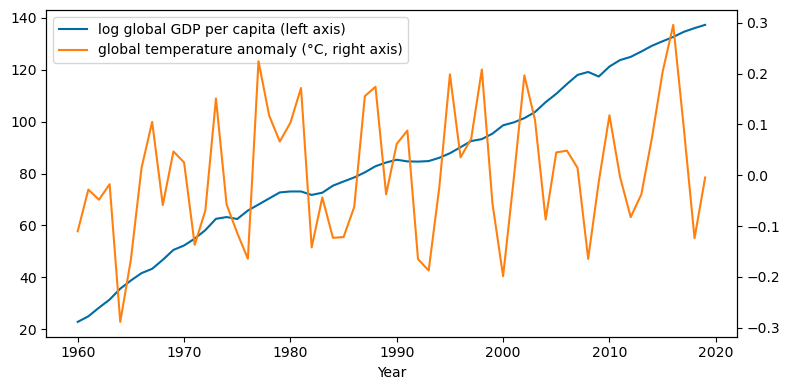

In [3]:
fig, ax1 = plt.subplots(figsize=(8, 4))
l1, = ax1.plot(df.index, df['l_gdp'], color='C0', label='log global GDP per capita (left axis)')
ax1.set_xlabel('Year')

ax2 = ax1.twinx()
l2, = ax2.plot(df.index, df['temp_anom'], color='C1', label='global temperature anomaly (°C, right axis)')

ax1.legend(handles=[l1, l2], loc='best')
plt.tight_layout()
fig.savefig('output/bk_gdp_temp.eps')
plt.show()

## Local projection

                            OLS Regression Results                            
Dep. Variable:              dl_gdp_h0   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.017
Method:                 Least Squares   F-statistic:                  0.004007
Date:                Wed, 03 Jun 2026   Prob (F-statistic):              0.950
Time:                        14:02:11   Log-Likelihood:                -100.84
No. Observations:                  59   AIC:                             205.7
Df Residuals:                      57   BIC:                             209.8
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.9419      0.217      8.936      0.0

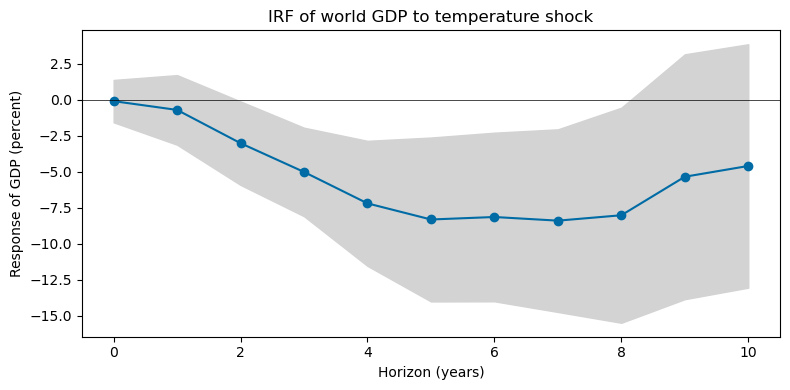

In [4]:
max_horizon = 10
T = df[['l_gdp', 'temp_anom']].dropna().shape[0]
nw_bw = int(np.ceil(0.75 * T**(1/3)))

irf = np.empty(max_horizon + 1)
se  = np.empty(max_horizon + 1)
for h in range(max_horizon + 1):
    y = (df['l_gdp'].shift(-h) - df['l_gdp'].shift(1)).rename(f'dl_gdp_h{h}')
    X = sm.add_constant(df[['temp_anom']])
    reg = sm.OLS(y, X, missing='drop').fit(
        cov_type='HAC',
        cov_kwds={'maxlags': nw_bw - 1}
        )
    if h <= 2:
        print(reg.summary())
        print('\n')
    irf[h] = reg.params['temp_anom']
    se[h]  = reg.bse['temp_anom']

# Plot IRF and confidence band
signif = 0.32 # significance level for confidence band
cv = norm.ppf(1 - signif / 2)

h_grid = np.arange(max_horizon + 1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(h_grid, irf, marker='o')
ax.fill_between(h_grid, irf - cv*se, irf + cv*se, color='lightgrey')
ax.axhline(0, color='k', linewidth=0.5)
ax.set_xlabel('Horizon (years)')
ax.set_ylabel('Response of GDP (percent)')
ax.set_title('IRF of world GDP to temperature shock')
plt.tight_layout()
fig.savefig('output/bk_irf_nocontrols.eps')
plt.show()

## Lag length selection

In [5]:
controls = ['l_gdp', 'temp_anom', 'lnpoil_wti', 'treasury1y', 'recessiondates']
var_model = sm.tsa.VAR(df[controls].dropna())
lag_order = var_model.select_order(maxlags=4)
print(lag_order.summary())

 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0       9.783       9.964   1.773e+04       9.853
1     0.5904*      1.675*      1.812*      1.011*
2      0.6255       2.615       1.918       1.397
3      0.8745       3.768       2.602       1.996
4      0.9227       4.720       3.050       2.395
-------------------------------------------------


## LP with controls

In [6]:
# Create lagged data
nlag = 2
df = df.assign(**{
    f'{var}_lag{l}': df[var].shift(l)
    for var in controls for l in range(1, nlag + 1)
})
lag_cols = [f'{var}_lag{l}' for var in controls for l in range(1, nlag + 1)]

In [7]:
def local_projection(df, outcome, shock, controls, max_horz):
    """Local projection IRF with SE"""
    irf = np.empty(max_horz + 1)
    se  = np.empty(max_horz + 1)
    for h in range(max_horz + 1):
        y = df[outcome].shift(-h)
        X = sm.add_constant(df[[shock] + controls])
        reg = sm.OLS(y, X, missing='drop').fit(cov_type='HC1')
        irf[h] = reg.params[shock]
        se[h]  = reg.bse[shock]
    return irf, se

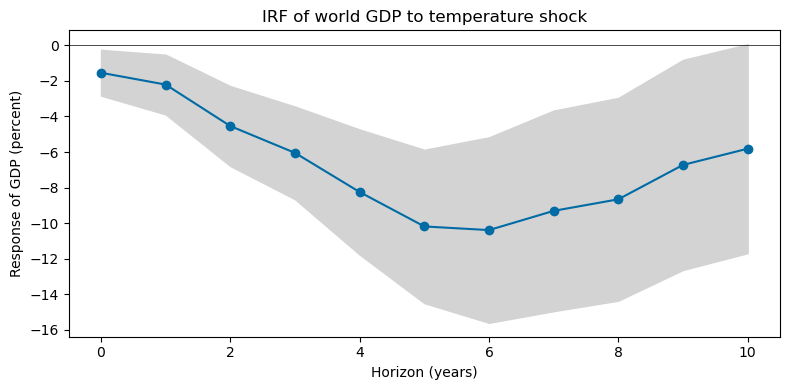

In [8]:
# LP with lagged controls
irf, se = local_projection(df, 'l_gdp', 'temp_anom', lag_cols, max_horizon)

# Plot
h_grid = np.arange(max_horizon + 1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(h_grid, irf, marker='o')
ax.fill_between(h_grid, irf - cv*se, irf + cv*se, color='lightgrey')
ax.axhline(0, color='k', linewidth=0.5)
ax.set_xlabel('Horizon (years)')
ax.set_ylabel('Response of GDP (percent)')
ax.set_title('IRF of world GDP to temperature shock')
plt.tight_layout()
fig.savefig('output/bk_irf_controls.eps')
plt.show()

## Shock predictability

In [9]:
df['dl_gdp_lag1']   = df['l_gdp'].diff().shift(1)
df['dlnpoil_lag1']  = df['lnpoil_wti'].diff().shift(1)

X = df[['dl_gdp_lag1', 'dlnpoil_lag1', 'temp_anom_lag1', 'treasury1y_lag1', 'recessiondates_lag1']]
reg = sm.OLS(df['temp_anom'], sm.add_constant(X), missing='drop').fit(cov_type='HC1')
print(reg.summary())

                            OLS Regression Results                            
Dep. Variable:              temp_anom   R-squared:                       0.155
Model:                            OLS   Adj. R-squared:                  0.074
Method:                 Least Squares   F-statistic:                     2.486
Date:                Wed, 03 Jun 2026   Prob (F-statistic):             0.0430
Time:                        14:02:11   Log-Likelihood:                 42.917
No. Observations:                  58   AIC:                            -73.83
Df Residuals:                      52   BIC:                            -61.47
Df Model:                           5                                         
Covariance Type:                  HC1                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   0.0483    

## Residual regression

In [10]:
# Multivariate regression
X = sm.add_constant(df[['temp_anom'] + lag_cols])
print(sm.OLS(df['l_gdp'], X, missing='drop').fit().summary())

# Residualized regression
df['temp_anom_resid'] = sm.OLS(df['temp_anom'], sm.add_constant(df[lag_cols]), missing='drop').fit().resid
print('\n')
print(sm.OLS(df['l_gdp'], sm.add_constant(df['temp_anom_resid']), missing='drop').fit().summary())


                            OLS Regression Results                            
Dep. Variable:                  l_gdp   R-squared:                       0.999
Model:                            OLS   Adj. R-squared:                  0.999
Method:                 Least Squares   F-statistic:                     3946.
Date:                Wed, 03 Jun 2026   Prob (F-statistic):           1.56e-64
Time:                        14:02:11   Log-Likelihood:                -79.599
No. Observations:                  58   AIC:                             183.2
Df Residuals:                      46   BIC:                             207.9
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   4.5430    

## Identification from timing restrictions

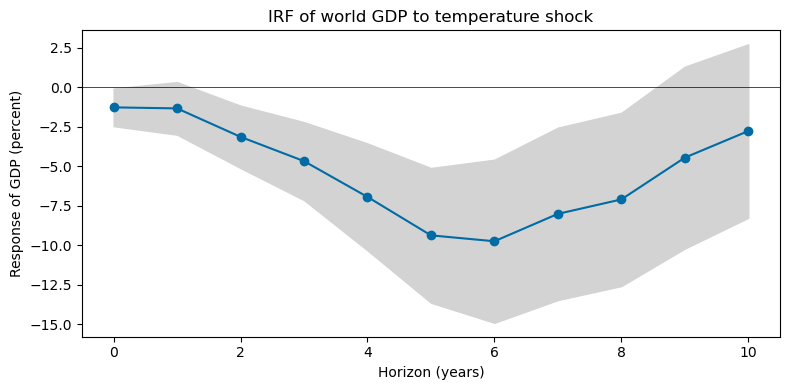

In [11]:
# LP with contemporaneous control
control_cols = ['recessiondates'] + lag_cols
irf, se = local_projection(df, 'l_gdp', 'temp_anom', control_cols, max_horizon)

# Plot
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(h_grid, irf, marker='o')
ax.fill_between(h_grid, irf - cv*se, irf + cv*se, color='lightgrey')
ax.axhline(0, color='k', linewidth=0.5)
ax.set_xlabel('Horizon (years)')
ax.set_ylabel('Response of GDP (percent)')
ax.set_title('IRF of world GDP to temperature shock')
plt.tight_layout()
fig.savefig('output/bk_irf_contemp.eps')
plt.show()

## Shock diagnostics

count    5.800000e+01
mean    -6.849406e-15
std      9.938751e-02
min     -2.344768e-01
25%     -6.508441e-02
50%     -5.863778e-03
75%      6.166066e-02
max      2.645975e-01
Name: temp_anom_resid, dtype: float64


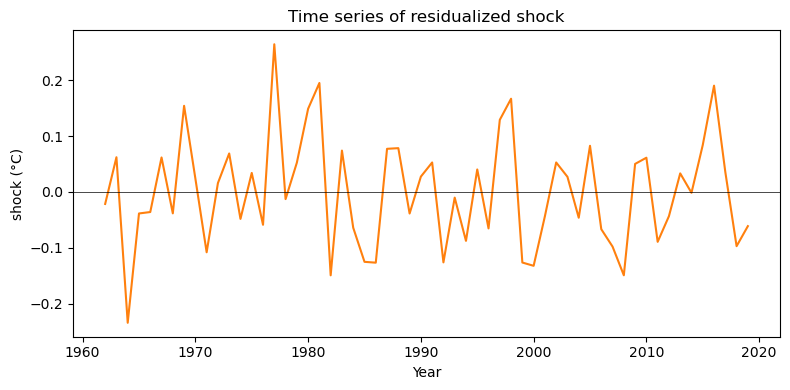

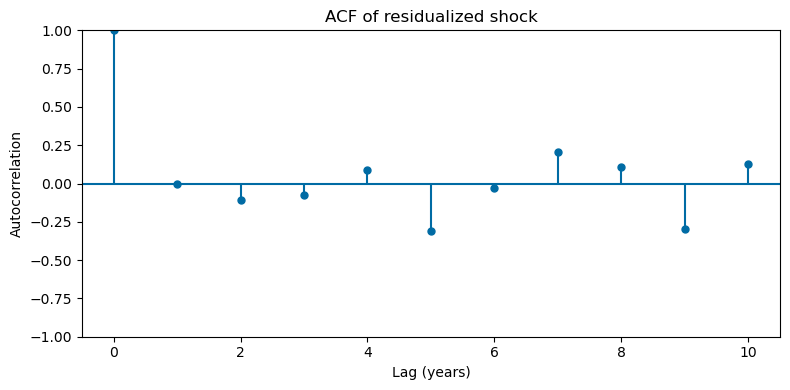

In [12]:
# Estimate shock on full sample, using all controls
df['temp_anom_resid'] = sm.OLS(df['temp_anom'], sm.add_constant(df[control_cols]), missing='drop').fit().resid

# Summary statistics
print(df['temp_anom_resid'].describe())

# Plot residualized shock
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(df.index, df['temp_anom_resid'], color='C1')
ax.axhline(0, color='k', linewidth=0.5)
ax.set_xlabel('Year')
ax.set_ylabel('shock (°C)')
ax.set_title('Time series of residualized shock')
plt.tight_layout()
fig.savefig('output/bk_shock.eps')
plt.show()

# ACF of residualized shock
fig, ax = plt.subplots(figsize=(8, 4))
sm.graphics.tsa.plot_acf(df['temp_anom_resid'].dropna(), lags=max_horizon,
                         alpha=None, ax=ax, title=None)
ax.set_xlabel('Lag (years)')
ax.set_ylabel('Autocorrelation')
ax.set_title('ACF of residualized shock')
plt.tight_layout()
fig.savefig('output/bk_shock_acf.eps')
plt.show()